Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine

In [2]:
DB_USER = "postgres"
DB_PASSWORD = "r1b1hu"
DB_HOST = "localhost"
DB_PORT = "5432"
DB_NAME = "sql_course"

engine = create_engine(
    f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

In [3]:
query = """
SELECT
    job_id,
    salary_year_avg
FROM job_postings_fact
WHERE job_title_short = 'Data Analyst'
  AND salary_year_avg IS NOT NULL;
"""

df_salary = pd.read_sql(query, engine)

df_salary.head()

,job_id,salary_year_avg
0,2604,85000.0
1,7565,50000.0
2,14027,75000.0
3,19387,110200.0
4,20951,62500.0


In [4]:
df_salary["salary_year_avg"].describe()

count      5463.000000
mean      93875.788390
std       34086.665076
min       25000.000000
25%       70000.000000
50%       90000.000000
75%      111175.000000
max      650000.000000
Name: salary_year_avg, dtype: float64

In [5]:
Q1 = df_salary["salary_year_avg"].quantile(0.25)
Q3 = df_salary["salary_year_avg"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_salary[
    (df_salary["salary_year_avg"] < lower_bound) |
    (df_salary["salary_year_avg"] > upper_bound)
]

print("Skewness:", df_salary["salary_year_avg"].skew())
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Total Outliers:", len(outliers))
print("Outlier Percentage:", round(len(outliers) / len(df_salary) * 100, 2), "%")

Skewness: 2.325141711945353
Lower Bound: 8237.5
Upper Bound: 172937.5
Total Outliers: 121
Outlier Percentage: 2.21 %


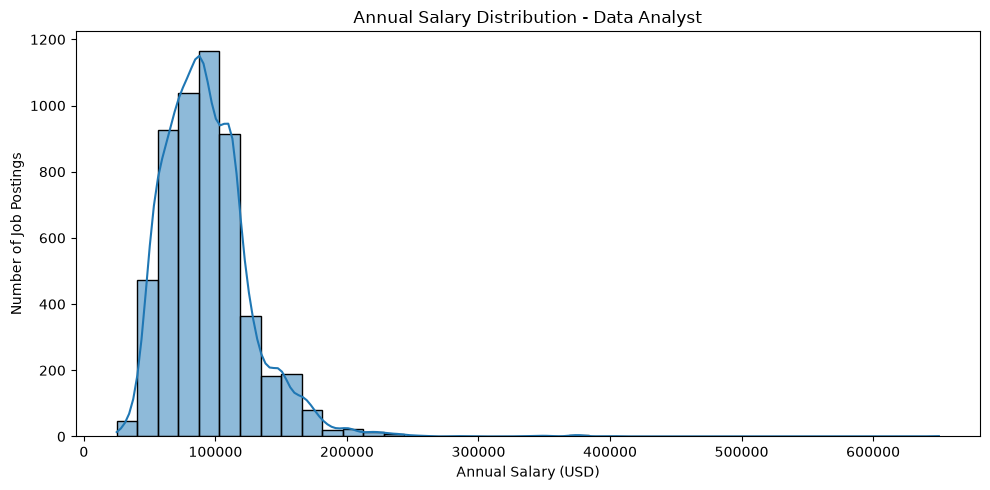

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_salary,
    x="salary_year_avg",
    bins=40,
    kde=True
)

plt.title("Annual Salary Distribution - Data Analyst")
plt.xlabel("Annual Salary (USD)")
plt.ylabel("Number of Job Postings")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

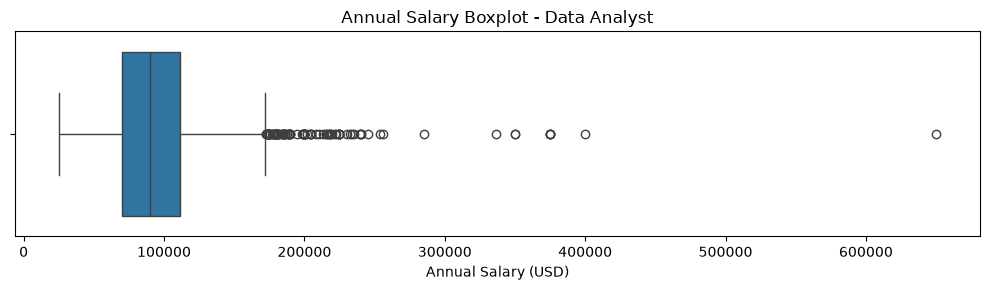

In [7]:
plt.figure(figsize=(10, 3))

sns.boxplot(
    x=df_salary["salary_year_avg"]
)

plt.title("Annual Salary Boxplot - Data Analyst")
plt.xlabel("Annual Salary (USD)")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

In [8]:
outliers.sort_values(
    by="salary_year_avg",
    ascending=False
).head(20)

,job_id,salary_year_avg
2489,226942,650000.0
2721,209315,400000.0
1620,1110602,375000.0
3984,1147675,375000.0
1871,641501,375000.0
4420,229253,375000.0
5332,101757,350000.0
1615,1059665,350000.0
3952,547382,336500.0
5281,894135,285000.0


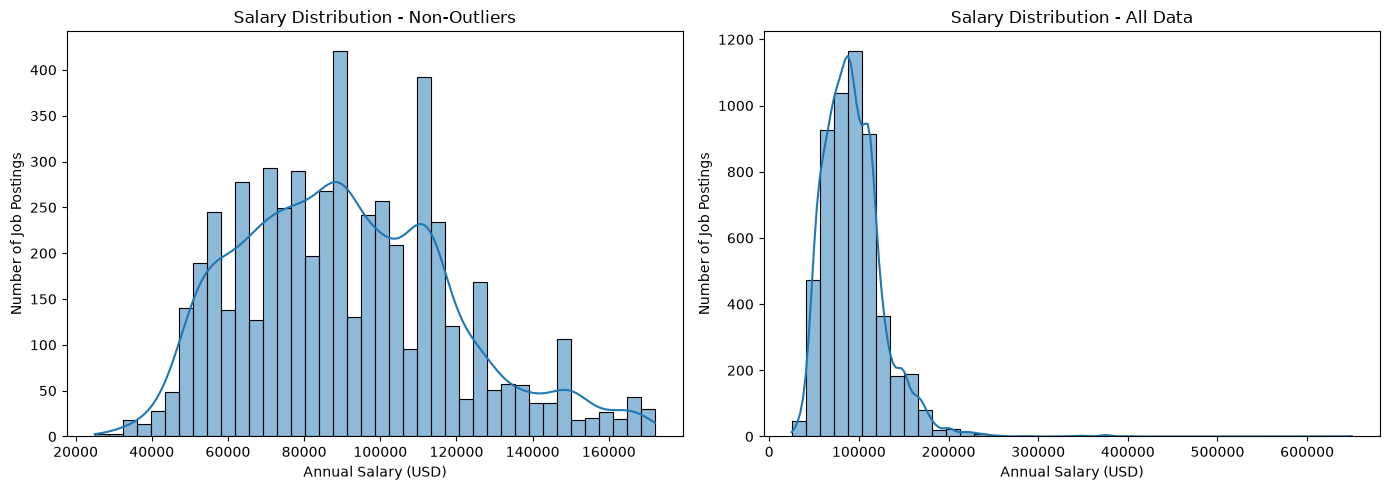

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung batas IQR
Q1 = df_salary["salary_year_avg"].quantile(0.25)
Q3 = df_salary["salary_year_avg"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

# Memisahkan data
df_non_outlier = df_salary[
    (df_salary["salary_year_avg"] >= lower_bound) &
    (df_salary["salary_year_avg"] <= upper_bound)
]

df_outlier = df_salary[
    (df_salary["salary_year_avg"] < lower_bound) |
    (df_salary["salary_year_avg"] > upper_bound)
]

# Membandingkan distribusi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df_non_outlier["salary_year_avg"],
    bins=40,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Salary Distribution - Non-Outliers")
axes[0].set_xlabel("Annual Salary (USD)")
axes[0].set_ylabel("Number of Job Postings")

sns.histplot(
    df_salary["salary_year_avg"],
    bins=40,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Salary Distribution - All Data")
axes[1].set_xlabel("Annual Salary (USD)")
axes[1].set_ylabel("Number of Job Postings")

for ax in axes:
    ax.ticklabel_format(style="plain", axis="x")

plt.tight_layout()
plt.show()